# Caso 1 · Cauce: clasificación automática de mensajes de clientes

**Equipo:** _completar nombres_

Este notebook sigue las consignas del enunciado (pasos 1 a 20). Cada paso tiene su celda; agreguen todas las que necesiten.
Las funciones de `src/` se completan en los archivos `.py`, no en el notebook. Antes de entregar: *Reiniciar y ejecutar todo*.

In [1]:
%load_ext autoreload
%autoreload 2
# autoreload vuelve a cargar los módulos de src/ cada vez que los modifican, sin reiniciar el notebook.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMILLA = 42

from src.limpieza import limpiar_texto
from src.naive_bayes import NaiveBayesMultinomial, terminos_mas_indicativos
from src.derivacion import REVISION, derivar, evaluar_derivacion

### Estado de las pruebas automáticas
Ejecuten esta celda cada vez que terminen una función de `src/`.

In [2]:
!python -m pytest -q --tb=no -rf

FFFF...........................                                          [100%]
=========================== short test summary info ===========================
FAILED tests/test_derivacion.py::test_derivar - NotImplementedError: Completa...
FAILED tests/test_derivacion.py::test_derivar_umbral_de_fraude_tiene_prioridad
FAILED tests/test_derivacion.py::test_derivar_sin_umbral_de_confianza_deriva_todo
FAILED tests/test_derivacion.py::test_evaluar_derivacion - NotImplementedErro...
4 failed, 27 passed in 1.91s


## Parte A · Exploración y línea base

**Paso 1.** Carguen `datos/mensajes_historicos.csv` e informen filas, nulos, mensajes vacíos, duplicados (mismo `id_cliente` y mismo `texto`), distribución de `equipo_final`, distribución por canal y cantidad de palabras por clase.

,Cantidad
Registros,8200
Textos nulos,11
Textos vacíos (incluye nulos y espacios),18
Duplicados por cliente y texto,200


,Tipo de dato,Nulos
id_mensaje,str,0
fecha_hora,str,0
id_cliente,str,0
canal,str,0
texto,str,11
equipo_derivado,str,0
equipo_final,str,0


,Mensajes,Porcentaje
equipo_final,,
transferencias,2552,31.12
tarjeta,2057,25.09
cuenta_acceso,1648,20.10
prestamos_inversiones,1029,12.55
fraude,914,11.15


,Mensajes
canal,
app_chat,3676
whatsapp,2499
email,1163
formulario_web,862


,Mensajes,Promedio,Mediana,Mínimo,Máximo
equipo_final,,,,,
cuenta_acceso,1648,13.87,13.0,0,46
fraude,914,18.22,17.0,0,50
prestamos_inversiones,1029,12.58,12.0,0,33
tarjeta,2057,14.81,14.0,0,42
transferencias,2552,16.95,17.0,0,41


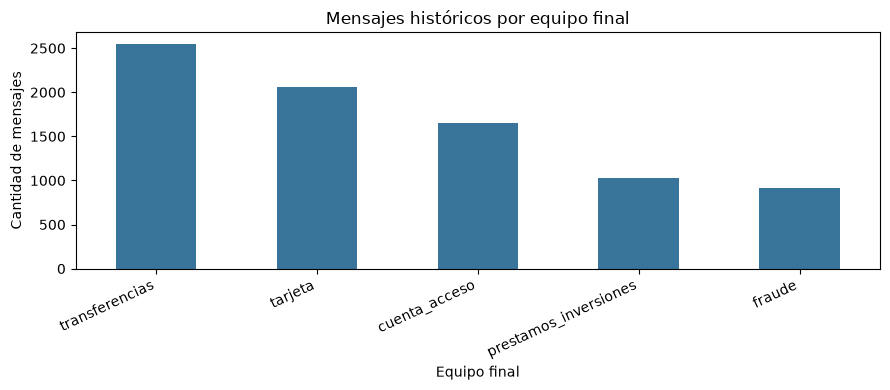

In [3]:
from IPython.display import display

df_original = pd.read_csv("datos/mensajes_historicos.csv")
cantidad_palabras_original = df_original["texto"].fillna("").str.split().str.len()
mensajes_vacios = df_original["texto"].fillna("").str.strip().eq("")
duplicados = df_original.duplicated(subset=["id_cliente", "texto"], keep="first")

resumen_original = pd.Series({
    "Registros": len(df_original),
    "Textos nulos": df_original["texto"].isna().sum(),
    "Textos vacíos (incluye nulos y espacios)": mensajes_vacios.sum(),
    "Duplicados por cliente y texto": duplicados.sum(),
}, name="Cantidad").to_frame()
display(resumen_original)
display(pd.DataFrame({
    "Tipo de dato": df_original.dtypes.astype(str),
    "Nulos": df_original.isna().sum(),
}))

distribucion_equipos = df_original["equipo_final"].value_counts().to_frame("Mensajes")
distribucion_equipos["Porcentaje"] = 100 * distribucion_equipos["Mensajes"] / len(df_original)
display(distribucion_equipos.round(2))
display(df_original["canal"].value_counts().to_frame("Mensajes"))

palabras_por_clase = (
    df_original.assign(palabras=cantidad_palabras_original)
    .groupby("equipo_final")["palabras"]
    .agg(["count", "mean", "median", "min", "max"])
    .rename(columns={"count": "Mensajes", "mean": "Promedio", "median": "Mediana", "min": "Mínimo", "max": "Máximo"})
)
display(palabras_por_clase.round(2))

ax = distribucion_equipos["Mensajes"].plot.bar(figsize=(9, 4), color="#39749b")
ax.set_title("Mensajes históricos por equipo final")
ax.set_xlabel("Equipo final")
ax.set_ylabel("Cantidad de mensajes")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

Transferencias concentra la mayor cantidad de mensajes y fraude es la clase con menos ejemplos. Hay textos nulos o vacíos y registros repetidos por cliente y texto. Los mensajes de fraude tienen el mayor promedio de palabras; los de préstamos e inversiones, el menor. Las tablas muestran los datos originales, antes de quitar registros.

**Paso 2.** Línea base de la mesa de entrada (`equipo_derivado` contra `equipo_final`): exactitud, F1 macro, matriz de confusión normalizada por fila y porcentaje de fraude derivado a otro equipo.

In [4]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

clases = np.sort(df_original["equipo_final"].unique())
y_real_manual = df_original["equipo_final"]
y_derivado_manual = df_original["equipo_derivado"]
es_fraude = y_real_manual.eq("fraude")
fraude_otro_equipo = es_fraude & y_derivado_manual.ne("fraude")
correctos_manuales = y_real_manual.eq(y_derivado_manual)

linea_base = pd.Series({
    "Mensajes originales": len(df_original),
    "Derivaciones correctas": correctos_manuales.sum(),
    "Derivaciones incorrectas": (~correctos_manuales).sum(),
    "Accuracy (%)": 100 * accuracy_score(y_real_manual, y_derivado_manual),
    "Errores (%)": 100 * (~correctos_manuales).mean(),
    "F1 macro": f1_score(y_real_manual, y_derivado_manual, labels=clases, average="macro", zero_division=0),
    "Mensajes reales de fraude": es_fraude.sum(),
    "Fraudes enviados a otro equipo": fraude_otro_equipo.sum(),
    "Fraudes enviados a otro equipo (%)": 100 * fraude_otro_equipo.sum() / es_fraude.sum(),
}, name="Resultado").to_frame()
display(linea_base.round(4))

matriz_manual = pd.DataFrame(
    confusion_matrix(y_real_manual, y_derivado_manual, labels=clases),
    index=pd.Index(clases, name="Equipo real"),
    columns=pd.Index(clases, name="Equipo derivado"),
)
matriz_manual_porcentaje = 100 * matriz_manual.div(matriz_manual.sum(axis=1), axis=0)
print("Matriz de confusión: cantidad de mensajes")
display(matriz_manual)
print("Matriz normalizada por fila: porcentaje de cada equipo real")
display(matriz_manual_porcentaje.round(2))

,Resultado
Mensajes originales,8200.0000
Derivaciones correctas,6774.0000
Derivaciones incorrectas,1426.0000
Accuracy (%),82.6098
Errores (%),17.3902
F1 macro,0.8166
Mensajes reales de fraude,914.0000
Fraudes enviados a otro equipo,290.0000
Fraudes enviados a otro equipo (%),31.7287


Matriz de confusión: cantidad de mensajes


Equipo derivado,cuenta_acceso,fraude,prestamos_inversiones,tarjeta,transferencias
Equipo real,,,,,
cuenta_acceso,1347,92,0,97,112
fraude,52,624,0,153,85
prestamos_inversiones,23,0,890,25,91
tarjeta,115,80,0,1722,140
transferencias,77,84,87,113,2191


Matriz normalizada por fila: porcentaje de cada equipo real


Equipo derivado,cuenta_acceso,fraude,prestamos_inversiones,tarjeta,transferencias
Equipo real,,,,,
cuenta_acceso,81.74,5.58,0.00,5.89,6.80
fraude,5.69,68.27,0.00,16.74,9.30
prestamos_inversiones,2.24,0.00,86.49,2.43,8.84
tarjeta,5.59,3.89,0.00,83.71,6.81
transferencias,3.02,3.29,3.41,4.43,85.85


La mesa de entrada acierta el 82,61% de las derivaciones y se equivoca en el 17,39%. De los 914 fraudes reales, 290 llegan a otro equipo (31,73%). Esta es la línea base manual: todavía no evaluamos un modelo sobre el histórico. Tiene sentido comparar una clasificación automática si permite reducir estos errores, especialmente los de fraude.

**Paso 3.** Eliminen los duplicados conservando el primero y expliquen por qué se hace antes de dividir.

In [5]:
df_sin_duplicados = df_original.drop_duplicates(subset=["id_cliente", "texto"], keep="first").copy()
duplicados_restantes = df_sin_duplicados.duplicated(subset=["id_cliente", "texto"]).sum()

display(pd.Series({
    "Registros originales": len(df_original),
    "Duplicados eliminados": len(df_original) - len(df_sin_duplicados),
    "Registros restantes": len(df_sin_duplicados),
    "Duplicados restantes por cliente y texto": duplicados_restantes,
}, name="Cantidad").to_frame())
assert duplicados_restantes == 0

,Cantidad
Registros originales,8200
Duplicados eliminados,200
Registros restantes,8000
Duplicados restantes por cliente y texto,0


Quitamos 200 duplicados y quedaron 8.000 mensajes, conservando la primera aparición. Lo hacemos antes de separar entrenamiento y prueba para evitar que un registro repetido aparezca en ambos conjuntos y mejore artificialmente la evaluación. Trabajamos sobre una copia; no cambiamos el CSV ni sus etiquetas.

## Parte B · Limpieza de texto (`src/limpieza.py`)

**Paso 4.** Implementen `quitar_tildes` y `limpiar_texto` en `src/limpieza.py` hasta que pasen `tests/test_limpieza.py`. Muestren aquí 5 ejemplos de texto original y limpio.

In [6]:
import subprocess
import sys

pruebas_limpieza = subprocess.run(
    [sys.executable, "-m", "pytest", "-q", "tests/test_limpieza.py"],
    capture_output=True, text=True, check=True,
)
print(pruebas_limpieza.stdout.strip())

# Ejemplos preparados para mostrar las reglas, sin tomar mensajes de clientes.
ejemplos_limpieza = [
    "¡NO PUEDO ENTRAR A MI CUENTA! 😡",
    "Me cobraron $ 15.000 dos veces.",
    "Transferí Gs. 8.350,50 y pagué USD20.",
    "Escribí a ayuda@example.com y entré a https://example.com/ayuda.",
    "La operación 123456 sigue pendiente.\nNecesito   ayuda.",
]
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame({
        "Texto original (inventado)": ejemplos_limpieza,
        "Texto limpio": [limpiar_texto(texto) for texto in ejemplos_limpieza],
    }))

...............                                                          [100%]
15 passed in 0.02s


,Texto original (inventado),Texto limpio
0,¡NO PUEDO ENTRAR A MI CUENTA! 😡,no puedo entrar a mi cuenta
1,Me cobraron $ 15.000 dos veces.,me cobraron _monto_ dos veces
2,"Transferí Gs. 8.350,50 y pagué USD20.",transferi _monto_ y pague _monto_
3,Escribí a ayuda@example.com y entré a https://example.com/ayuda.,escribi a _email_ y entre a _url_
4,La operación 123456 sigue pendiente.\nNecesito ayuda.,la operacion _num_ sigue pendiente necesito ayuda


Los cinco ejemplos son inventados. La limpieza unifica mayúsculas y tildes, reemplaza URL, correos, montos y números por tokens y compacta espacios. Los guiones bajos de esos tokens se conservan. No quitamos palabras comunes ni agregamos otras transformaciones.

**Paso 5.** Creen la columna `texto_limpio`. Los mensajes con menos de dos palabras se excluyen del entrenamiento y van a revisión humana: ¿cuántos son y qué contienen?

In [7]:
df_preparado = df_sin_duplicados.copy()
df_preparado["texto_limpio"] = df_preparado["texto"].map(limpiar_texto)
df_preparado["cantidad_palabras_limpias"] = df_preparado["texto_limpio"].str.split().str.len()
mascara_revision = df_preparado["cantidad_palabras_limpias"].lt(2)
mascara_entrenamiento = ~mascara_revision

# Se conservan los índices y los identificadores en memoria para ubicar cada registro.
df_revision = df_preparado.loc[mascara_revision].copy()
df_entrenamiento = df_preparado.loc[mascara_entrenamiento].copy()

display(pd.Series({
    "Mensajes sin duplicados": len(df_preparado),
    "Mensajes con texto_limpio calculado": df_preparado["texto_limpio"].notna().sum(),
    "Textos limpios no vacíos": df_preparado["texto_limpio"].ne("").sum(),
    "Mensajes con menos de dos palabras (revisión)": mascara_revision.sum(),
    "Mensajes aptos para entrenamiento": mascara_entrenamiento.sum(),
}, name="Cantidad").to_frame())
display(df_revision["equipo_final"].value_counts().reindex(clases, fill_value=0).to_frame("Mensajes cortos"))

tipo_contenido_corto = np.select(
    [
        df_revision["texto_limpio"].eq(""),
        df_revision["texto_limpio"].eq("_num_"),
        df_revision["texto_limpio"].eq("_monto_"),
        df_revision["texto_limpio"].eq("_url_"),
        df_revision["texto_limpio"].eq("_email_"),
    ],
    ["Vacío después de limpiar", "Sólo número", "Sólo monto", "Sólo URL", "Sólo correo"],
    default="Una palabra",
)
display(pd.Series(tipo_contenido_corto, name="Contenido").value_counts().to_frame("Mensajes"))
assert len(df_entrenamiento) + len(df_revision) == len(df_preparado)
assert df_entrenamiento["cantidad_palabras_limpias"].ge(2).all()

,Cantidad
Mensajes sin duplicados,8000
Mensajes con texto_limpio calculado,8000
Textos limpios no vacíos,7952
Mensajes con menos de dos palabras (revisión),70
Mensajes aptos para entrenamiento,7930


,Mensajes cortos
equipo_final,
cuenta_acceso,16
fraude,6
prestamos_inversiones,14
tarjeta,18
transferencias,16


,Mensajes
Contenido,
Vacío después de limpiar,48
Una palabra,22


La limpieza se aplicó a los 8.000 mensajes sin duplicados. Quedaron 7.952 textos no vacíos; 70 mensajes tienen menos de dos palabras y se reservan para revisión humana. De esos 70, 48 quedan vacíos y 22 contienen una sola palabra: no alcanzan para describir el problema con suficiente contexto. Los 7.930 restantes quedan preparados para entrenamiento, sin dividirlos ni entrenar un modelo todavía. Las máscaras y las copias mantienen los índices e identificadores originales, pero sólo mostramos agregados.

## Parte C · Naive Bayes desde cero (`src/naive_bayes.py`)

**Paso 6.** Implementen `log_suma_exp`, `NaiveBayesMultinomial` y `terminos_mas_indicativos` hasta que pasen `tests/test_naive_bayes.py`.

In [8]:
from sklearn.feature_extraction.text import CountVectorizer

pruebas_naive_bayes = subprocess.run(
    [sys.executable, "-m", "pytest", "-q", "tests/test_naive_bayes.py"],
    capture_output=True, text=True, check=True,
)
print(pruebas_naive_bayes.stdout.strip())

# Demostración con mensajes inventados; no se entrena con el histórico de Cauce.
textos_demo = [
    "no puedo ingresar a mi cuenta",
    "necesito recuperar la clave de mi cuenta",
    "me rechazaron la tarjeta",
    "no puedo activar mi tarjeta",
    "no reconozco esta transferencia",
    "hicieron una transferencia que no reconozco",
]
etiquetas_demo = ["cuenta_acceso", "cuenta_acceso", "tarjeta", "tarjeta", "fraude", "fraude"]
vectorizador_demo = CountVectorizer()
X_demo = vectorizador_demo.fit_transform([limpiar_texto(texto) for texto in textos_demo])
modelo_demo = NaiveBayesMultinomial(alpha=1).fit(X_demo, etiquetas_demo)

consultas_demo = [
    "no puedo ingresar a mi cuenta",
    "me rechazaron la tarjeta",
    "no reconozco esta transferencia",
]
X_consultas_demo = vectorizador_demo.transform([limpiar_texto(texto) for texto in consultas_demo])
probabilidades_demo = modelo_demo.predict_proba(X_consultas_demo)
predicciones_demo = modelo_demo.predict(X_consultas_demo)
resultado_demo = pd.DataFrame({"Mensaje inventado": consultas_demo, "Clase predicha": predicciones_demo})
for indice, clase in enumerate(modelo_demo.classes_):
    resultado_demo[f"P({clase})"] = probabilidades_demo[:, indice]
display(resultado_demo.round(4))
np.testing.assert_allclose(probabilidades_demo.sum(axis=1), 1.0)

............                                                             [100%]
12 passed in 1.98s


,Mensaje inventado,Clase predicha,P(cuenta_acceso),P(fraude),P(tarjeta)
0,no puedo ingresar a mi cuenta,cuenta_acceso,0.8069,0.0464,0.1467
1,me rechazaron la tarjeta,tarjeta,0.0514,0.0333,0.9153
2,no reconozco esta transferencia,fraude,0.0267,0.9337,0.0396


Naive Bayes suma conteos de términos por clase, aplica suavizado y combina logaritmos para evitar underflow. `log_suma_exp` normaliza los puntajes para obtener probabilidades; la clase con la mayor probabilidad es la predicción. Las pruebas verifican el cálculo manual, la equivalencia numérica con scikit-learn, las matrices dispersas y la compatibilidad con Pipeline y GridSearchCV. La tabla usa un conjunto didáctico pequeño: muestra que el código funciona, pero sus probabilidades no son una evaluación del caso Cauce. El análisis de términos del histórico queda para el paso 9.

**Paso 7.** División 80/20 estratificada por `equipo_final` con `random_state=42`.

In [ ]:
# Tu código aquí

**Paso 8.** `CountVectorizer` + su clase y la de scikit-learn con `alpha=1`: muestren que predicen lo mismo en el 100% de los mensajes de prueba.

In [ ]:
# Tu código aquí

**Paso 9.** Los 10 términos más indicativos de cada clase y su interpretación para el negocio.

In [ ]:
# Tu código aquí

## Parte D · Ajuste y comparación con KNN

**Paso 10.** `GridSearchCV` del pipeline `CountVectorizer` + `NaiveBayesMultinomial` (5 particiones estratificadas, `f1_macro`). Conclusión sobre cada hiperparámetro.

In [ ]:
# Tu código aquí

**Paso 11.** Misma búsqueda con `TfidfVectorizer` + `KNeighborsClassifier(metric="cosine", algorithm="brute")`. ¿Por qué coseno y no euclídea?

In [ ]:
# Tu código aquí

**Paso 12.** Tiempo de predicción de 1.000 mensajes con 25%, 50%, 75% y 100% del entrenamiento, para los dos modelos. Gráfico y explicación.

In [ ]:
# Tu código aquí

## Parte E · Regla de derivación y evaluación (`src/derivacion.py`)

**Paso 13.** Implementen `derivar` y `evaluar_derivacion` hasta que pasen `tests/test_derivacion.py`.

In [ ]:
# Tu código aquí

**Paso 14.** Probabilidades fuera de muestra con `cross_val_predict` y elección de los dos umbrales (con margen de seguridad) para Naive Bayes y para KNN.

In [ ]:
# Tu código aquí

**Paso 15.** Evaluación única en prueba: tabla con los cinco indicadores de aceptación para Naive Bayes, KNN y la mesa de entrada; reporte de clasificación y matriz de confusión del modelo elegido.

In [ ]:
# Tu código aquí

**Paso 16.** Análisis de 10 errores de derivación automática: causa de cada uno y una mejora concreta.

In [ ]:
# Tu código aquí

**Paso 17.** Impacto en un día de 6.500 mensajes.

In [ ]:
# Tu código aquí

## Parte F · Predicción de los mensajes nuevos

**Paso 18.** Reentrenen el modelo elegido con todos los mensajes históricos limpios y apliquen la regla a `datos/mensajes_nuevos.csv`.

In [ ]:
# Tu código aquí

**Paso 19.** Generen `predicciones_caso1.csv` (2.040 filas; columnas `id_mensaje`, `equipo_predicho`, `prob_max`, `prob_fraude`, `derivacion`) y verifiquen el formato.

In [ ]:
# Tu código aquí

## Parte G · Informe ejecutivo

**Paso 20.** El informe para Laura Benítez se entrega aparte, en `informe_ejecutivo.pdf`.

## Preguntas de reflexión profesional

Respondan cada pregunta en un párrafo, apoyándose en sus resultados.

**1. Naive Bayes supone que las palabras son independientes dada la clase. ¿Por qué clasifica bien igual? ¿Qué consecuencia tiene esa suposición sobre las probabilidades?**

_Respuesta:_ 

**2. ¿Qué pasaría con `alpha=0` si aparece una palabra que nunca se vio en la clase `fraude`?**

_Respuesta:_ 

**3. ¿Por qué `equipo_derivado` no puede usarse como variable del modelo?**

_Respuesta:_ 

**4. ¿Qué costo tendría KNN en producción comparado con Naive Bayes? ¿En qué situación elegirían KNN igual?**

_Respuesta:_ 

**5. ¿Quién debería fijar el máximo de fraude perdido y la exactitud mínima? ¿Qué información tiene que llevar el equipo de datos?**

_Respuesta:_ 

**6. Si Cauce lanza un seguro para celulares, ¿qué le pasa al modelo y cómo lo detectarían en producción?**

_Respuesta:_ 

**7. ¿Qué datos personales anonimizarían antes de guardar los datos de entrenamiento y cómo afectaría al modelo?**

_Respuesta:_ 